# Anchor × category interactions — v1 (merchant_risk_score)

Plan: `anchor_pocket_mining_plan.md` (same folder). Chain: observation →
hypothesis → data → tests; FE/model only if something passes.

Question: which categorical columns change what a merchant_risk anchor
means — is P(fraud | anchor, value) different from P(fraud | anchor)
beyond sampling noise, consistently across anchors?

Three tests, fixed before looking:

1. **Cell scan** — per (anchor, value) cell (>= 500 rows), two-proportion
   z of the cell rate vs its anchor's pooled rate; count |z| >= 3.
2. **Within-anchor shuffle** — permute each partner's labels among each
   anchor's rows (20 draws), recount. A partner is meaningful only if the
   observed count exceeds every shuffle.
3. **Value-level lift** — for meaningful partners: frauds observed at a
   value ÷ frauds expected if the value were indifferent inside its
   anchors (bootstrap CI); anchor × value heat maps show where.

Rates are pooled (descriptive scan; any feature built from this will be
fold-safe).

In [1]:
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ccf_ml.cross_validation.constants import TARGET_COLUMN
from ccf_ml.file_utils import get_script_plot_dir, get_train_csv_path

COLUMN = "merchant_risk_score"
PARTNERS = [
    "merchant_category", "card_type", "auth_method", "channel",
    "device_type", "is_foreign_transaction", "is_new_merchant", "used_vpn",
    "ip_country_mismatch", "billing_shipping_mismatch",
    "is_ai_generated_scam_attempt",
]
MIN_CELL_ROWS = 500
MIN_FRAUDS_RATIO = 10
Z_THRESHOLD = 3.0
N_SHUFFLE = 20
B = 200
rng = np.random.default_rng(42)

train = pd.read_csv(get_train_csv_path())
y = train[TARGET_COLUMN].to_numpy(dtype=bool)
anchor = np.floor(train[COLUMN].to_numpy(dtype=np.float64)).astype(np.int64)

# sort rows by anchor once; anchor blocks are contiguous for fast shuffles
order = np.argsort(anchor, kind="stable")
anchor_sorted = anchor[order]
y_sorted = y[order]
block_ends = np.r_[np.flatnonzero(anchor_sorted[1:] != anchor_sorted[:-1]) + 1, len(anchor_sorted)]
block_starts = np.r_[0, block_ends[:-1]]

anchor_tot = pd.DataFrame({"a": anchor_sorted, "y": y_sorted}).groupby("a")["y"].agg(f="sum", n="size")
p_anchor = (anchor_tot["f"] / anchor_tot["n"]).to_dict()

plot_dir = get_script_plot_dir(
    "anchor_category_interactions_v1", section="scan", group="numerical_grid_structure"
)
print("rows:", len(train), "| anchors:", len(anchor_tot), "| plots ->", plot_dir)

rows: 699960 | anchors: 98 | plots -> C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\numerical_grid_structure\anchor_category_interactions_v1\plots\scan


In [2]:
# Test 1 + 2: cell scan and within-anchor shuffle gate, per partner
def deviating_cells(partner_values_sorted: np.ndarray) -> tuple[int, int]:
    """Count |z|>=3 cells and cells tested for one partner label array."""
    df = pd.DataFrame(
        {"a": anchor_sorted, "v": partner_values_sorted, "y": y_sorted}
    )
    cell = df.groupby(["a", "v"])["y"].agg(f="sum", n="size").reset_index()
    cell = cell[cell["n"] >= MIN_CELL_ROWS]
    if cell.empty:
        return 0, 0
    cell["p_a"] = cell["a"].map(p_anchor)
    cell["n_a"] = cell["a"].map(anchor_tot["n"])
    var = cell["p_a"] * (1 - cell["p_a"]) * (1 / cell["n"] - 1 / cell["n_a"])
    z = (cell["f"] / cell["n"] - cell["p_a"]) / np.sqrt(var)
    return int((z.abs() >= Z_THRESHOLD).sum()), len(cell)

scan_rows = []
partner_arrays = {}
for partner in PARTNERS:
    vals = train[partner].to_numpy()[order]
    partner_arrays[partner] = vals
    n_dev, n_cells = deviating_cells(vals)
    shuffle_max = []
    for _ in range(N_SHUFFLE):
        perm = vals.copy()
        for s, e in zip(block_starts, block_ends):
            perm[s:e] = vals[s:e][rng.permutation(e - s)]
        shuffle_max.append(deviating_cells(perm)[0])
    shuffle_max = np.array(shuffle_max)
    expected = 0.0027 * n_cells
    scan_rows.append({
        "partner": partner,
        "cells tested": n_cells,
        "|z|>=3 observed": n_dev,
        "expected (noise)": round(expected, 1),
        "shuffle median": float(np.median(shuffle_max)),
        "shuffle max": int(shuffle_max.max()),
        "obs/shuffle_max": round(n_dev / max(shuffle_max.max(), 1), 2),
        "meaningful": bool(n_dev > shuffle_max.max()),
    })
    print(
        f"{partner:28s} cells={n_cells:5d} |z|>=3: obs={n_dev:4d} "
        f"noise~{expected:5.1f} shuffle med/max={np.median(shuffle_max):5.1f}/{shuffle_max.max():4d}"
    )
scan = pd.DataFrame(scan_rows)
display(scan)

merchant_category            cells=  348 |z|>=3: obs=  22 noise~  0.9 shuffle med/max=  1.0/   4


card_type                    cells=  195 |z|>=3: obs=   0 noise~  0.5 shuffle med/max=  0.0/   2


auth_method                  cells=  246 |z|>=3: obs= 103 noise~  0.7 shuffle med/max=  1.0/   2


channel                      cells=  230 |z|>=3: obs=   0 noise~  0.6 shuffle med/max=  0.0/   2


device_type                  cells=  296 |z|>=3: obs=   1 noise~  0.8 shuffle med/max=  0.0/   3


is_foreign_transaction       cells=   72 |z|>=3: obs=  59 noise~  0.2 shuffle med/max=  0.0/   1


... (2 outputs left out)

ip_country_mismatch          cells=   72 |z|>=3: obs=  62 noise~  0.2 shuffle med/max=  0.0/   2


billing_shipping_mismatch    cells=   72 |z|>=3: obs=  55 noise~  0.2 shuffle med/max=  0.0/   2


is_ai_generated_scam_attempt cells=   72 |z|>=3: obs=  44 noise~  0.2 shuffle med/max=  1.0/   4


,partner,cells tested,|z|>=3 observed,expected (noise),shuffle median,shuffle max,obs/shuffle_max,meaningful
0,merchant_category,348,22,0.9,1.0,4,5.50,True
1,card_type,195,0,0.5,0.0,2,0.00,False
2,auth_method,246,103,0.7,1.0,2,51.50,True
3,channel,230,0,0.6,0.0,2,0.00,False
4,device_type,296,1,0.8,0.0,3,0.33,False
5,is_foreign_transaction,72,59,0.2,0.0,1,59.00,True
6,is_new_merchant,116,100,0.3,0.0,3,33.33,True
7,used_vpn,94,78,0.3,0.0,3,26.00,True
8,ip_country_mismatch,72,62,0.2,0.0,2,31.00,True
9,billing_shipping_mismatch,72,55,0.2,0.0,2,27.50,True


In [3]:
# effect sizes for every partner: strongest cell rate ratios (readable units)
ratio_rows = []
for partner in PARTNERS:
    vals = partner_arrays[partner]
    df = pd.DataFrame({"a": anchor_sorted, "v": vals, "y": y_sorted})
    cell = df.groupby(["a", "v"])["y"].agg(f="sum", n="size").reset_index()
    cell = cell[(cell["n"] >= MIN_CELL_ROWS) & (cell["f"] >= MIN_FRAUDS_RATIO)]
    cell["p_a"] = cell["a"].map(p_anchor)
    cell["ratio"] = (cell["f"] / cell["n"]) / cell["p_a"]
    up = cell.loc[cell["ratio"].idxmax()]
    down = cell.loc[cell["ratio"].idxmin()]
    ratio_rows.append({
        "partner": partner,
        "strongest up": f"{up['ratio']:.2f}x at anchor {int(up['a'])}, value {up['v']} (n={int(up['n'])}, {int(up['f'])} frauds)",
        "strongest down": f"{down['ratio']:.2f}x at anchor {int(down['a'])}, value {down['v']} (n={int(down['n'])}, {int(down['f'])} frauds)",
    })
pd.DataFrame(ratio_rows)

,partner,strongest up,strongest down
0,merchant_category,"2.54x at anchor 24, value Travel (n=900, 10 fr...","0.51x at anchor 55, value Groceries (n=651, 15..."
1,card_type,"1.73x at anchor 15, value Visa (n=3479, 12 fra...","0.71x at anchor 22, value Mastercard (n=5600, ..."
2,auth_method,"6.70x at anchor 20, value No Authentication (n...","0.23x at anchor 44, value Biometric (n=1952, 1..."
3,channel,"1.61x at anchor 60, value POS (n=685, 12 frauds)","0.60x at anchor 36, value Contactless (n=3195,..."
4,device_type,"1.92x at anchor 19, value Android Phone (n=408...","0.64x at anchor 25, value Android Phone (n=702..."
5,is_foreign_transaction,"0.97x at anchor 19, value False (n=11566, 20 f...","0.84x at anchor 17, value False (n=8827, 23 fr..."
6,is_new_merchant,"3.60x at anchor 18, value True (n=1632, 14 fra...","0.54x at anchor 18, value False (n=9282, 12 fr..."
7,used_vpn,"6.57x at anchor 29, value True (n=635, 26 frauds)","0.80x at anchor 61, value False (n=2772, 34 fr..."
8,ip_country_mismatch,"0.98x at anchor 18, value False (n=10736, 25 f...","0.72x at anchor 17, value False (n=8864, 20 fr..."
9,billing_shipping_mismatch,"1.01x at anchor 64, value False (n=930, 14 fra...","0.77x at anchor 19, value False (n=11608, 16 f..."


meaningful partners: ['merchant_category', 'auth_method', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']


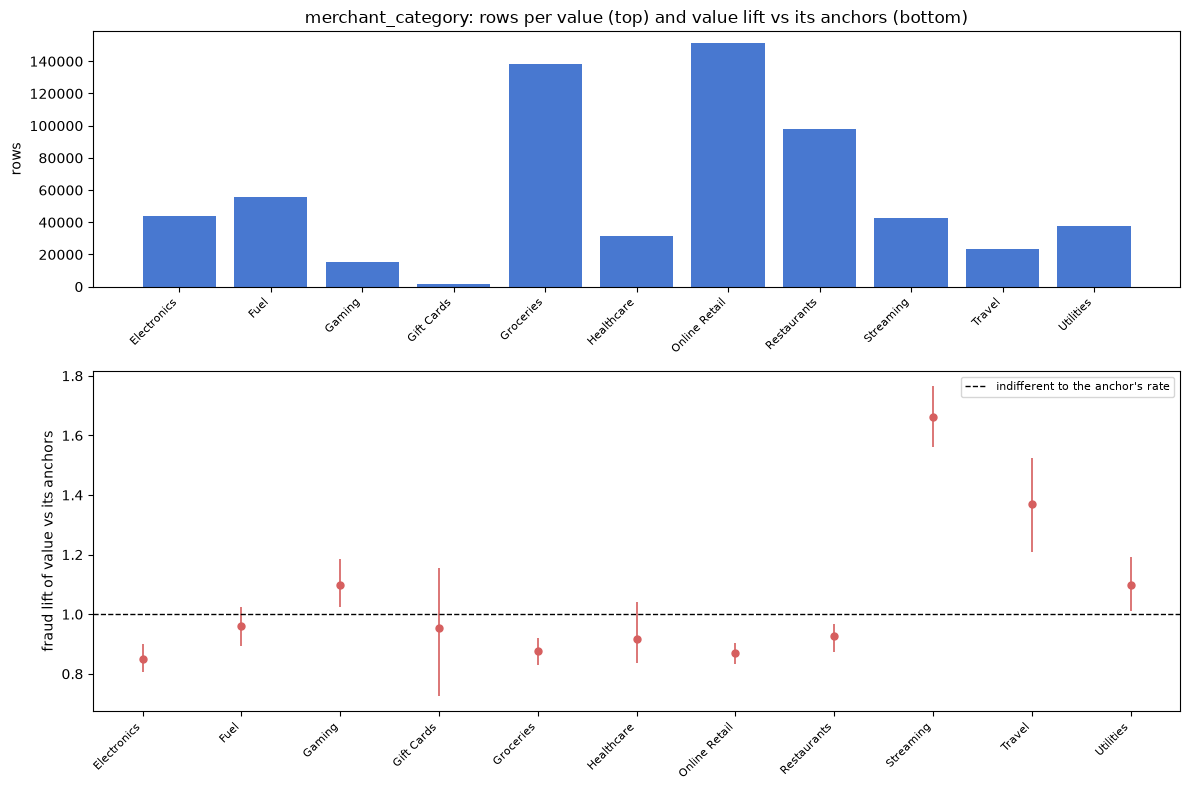

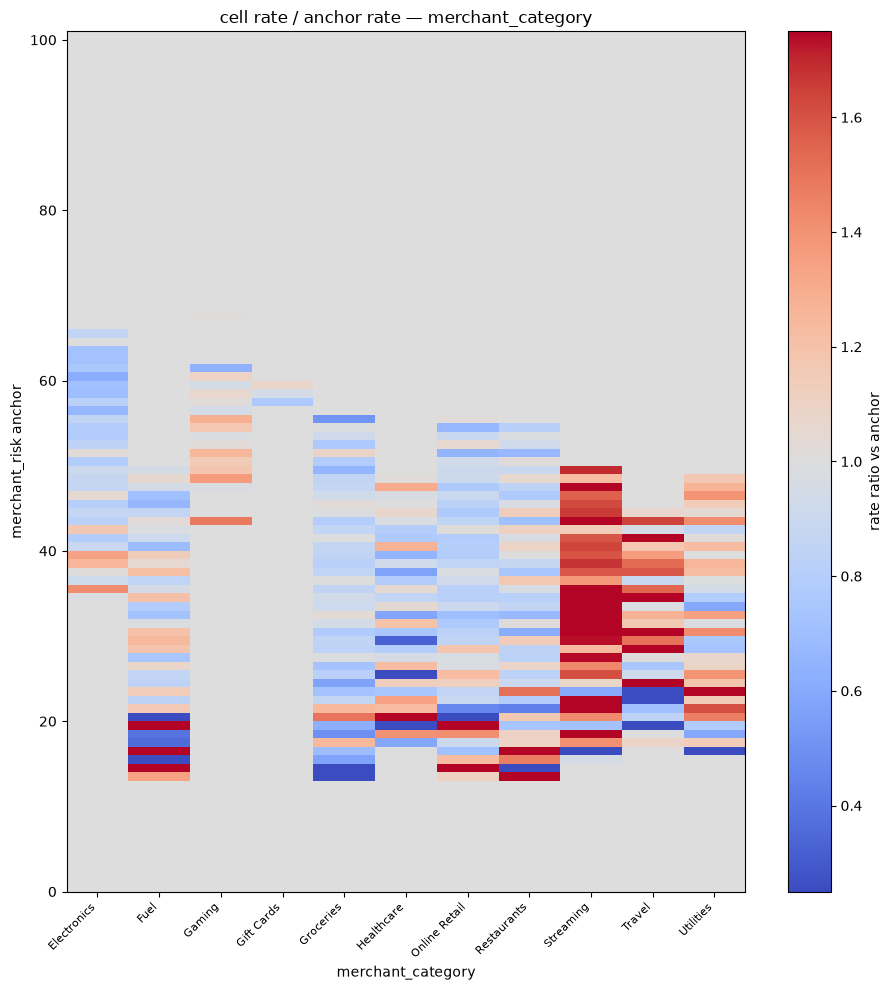

,obs,exp,n,lift
v,,,,
Electronics,1240,1460.333,43648,0.849
Fuel,621,645.437,55990,0.962
Gaming,612,558.121,15589,1.097
Gift Cards,67,70.247,1802,0.954
Groceries,1520,1734.548,138212,0.876
Healthcare,358,390.082,31559,0.918
Online Retail,1667,1915.968,151053,0.870
Restaurants,1105,1192.219,97995,0.927
Streaming,868,522.098,42804,1.663


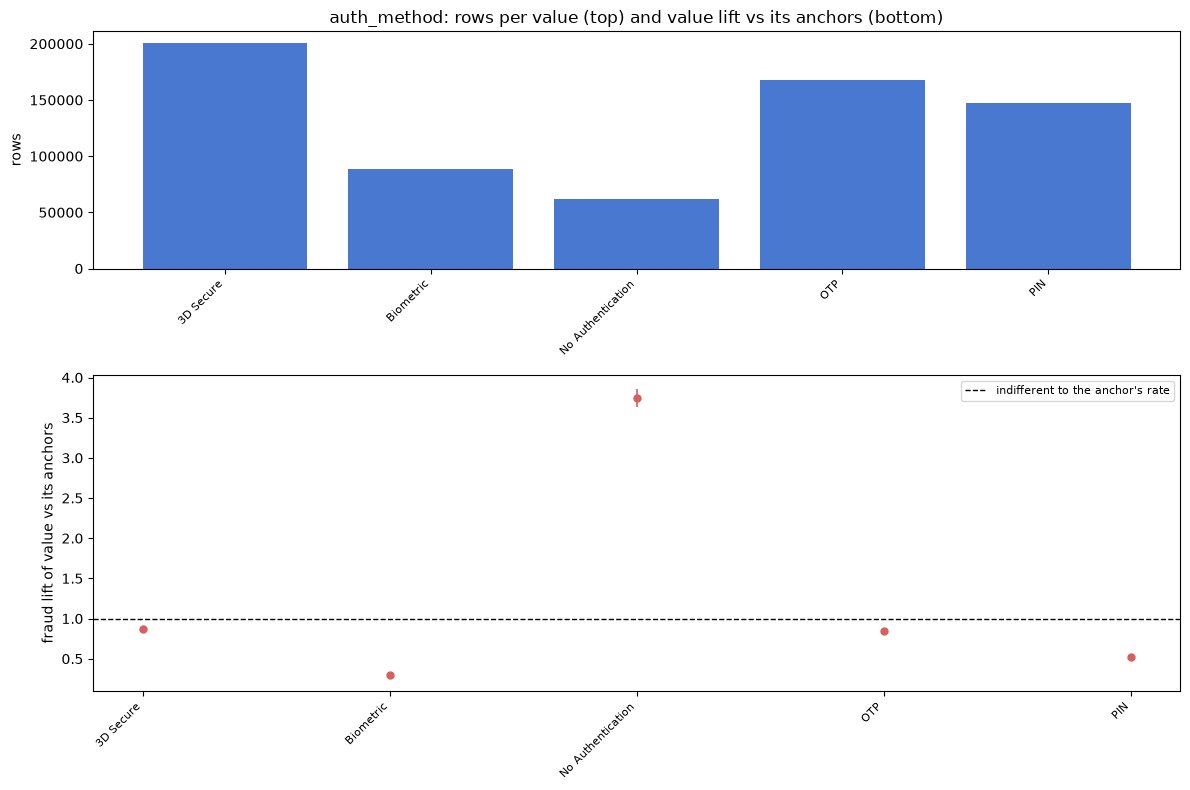

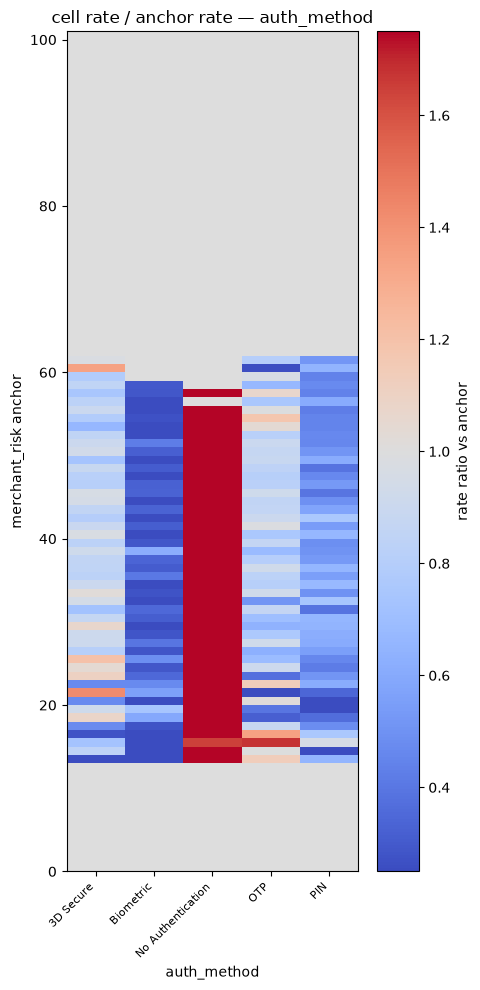

,obs,exp,n,lift
v,,,,
3D Secure,2529,2918.232,201006,0.867
Biometric,381,1259.985,88444,0.302
No Authentication,3390,905.416,62156,3.744
OTP,2052,2425.879,167908,0.846
PIN,1119,2125.037,147399,0.527


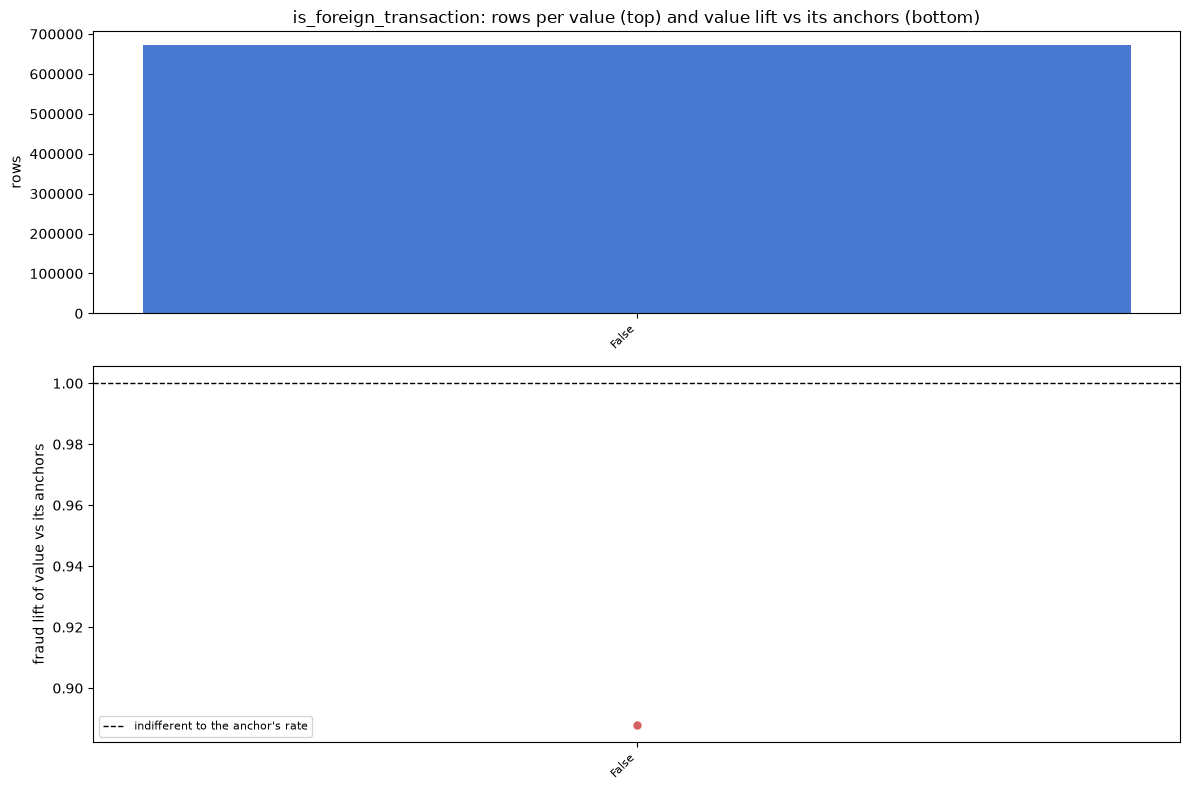

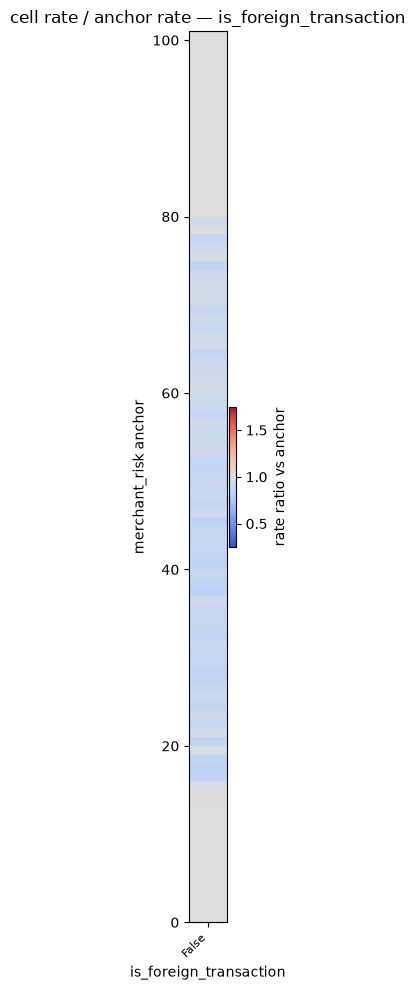

,obs,exp,n,lift
v,,,,
False,10050,11319.318,673061,0.888


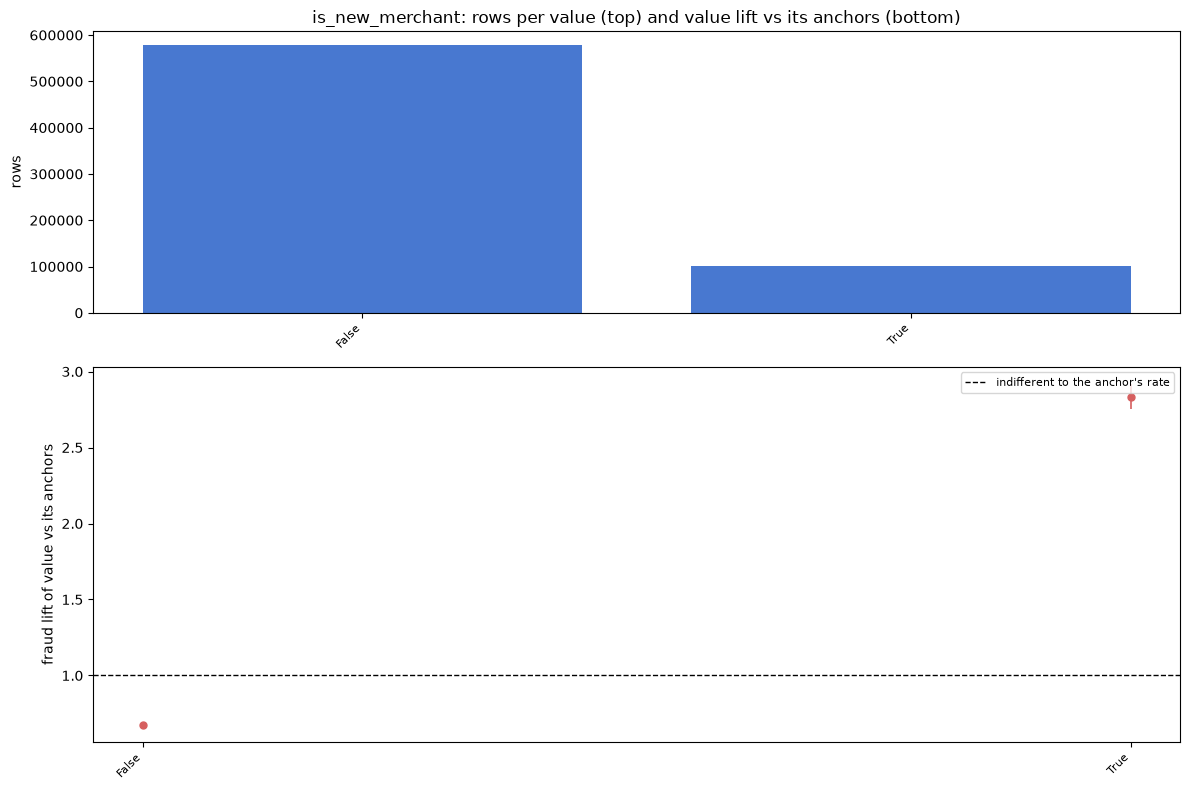

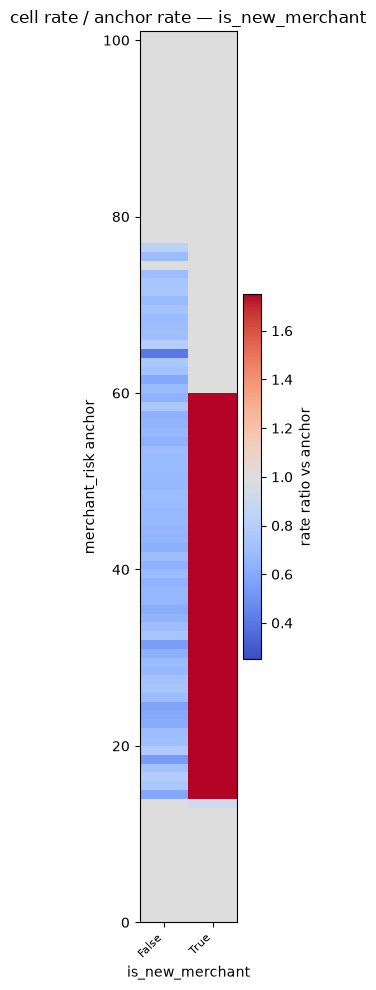

,obs,exp,n,lift
v,,,,
False,6395,9502.554,579089,0.673
True,4230,1494.498,101128,2.830


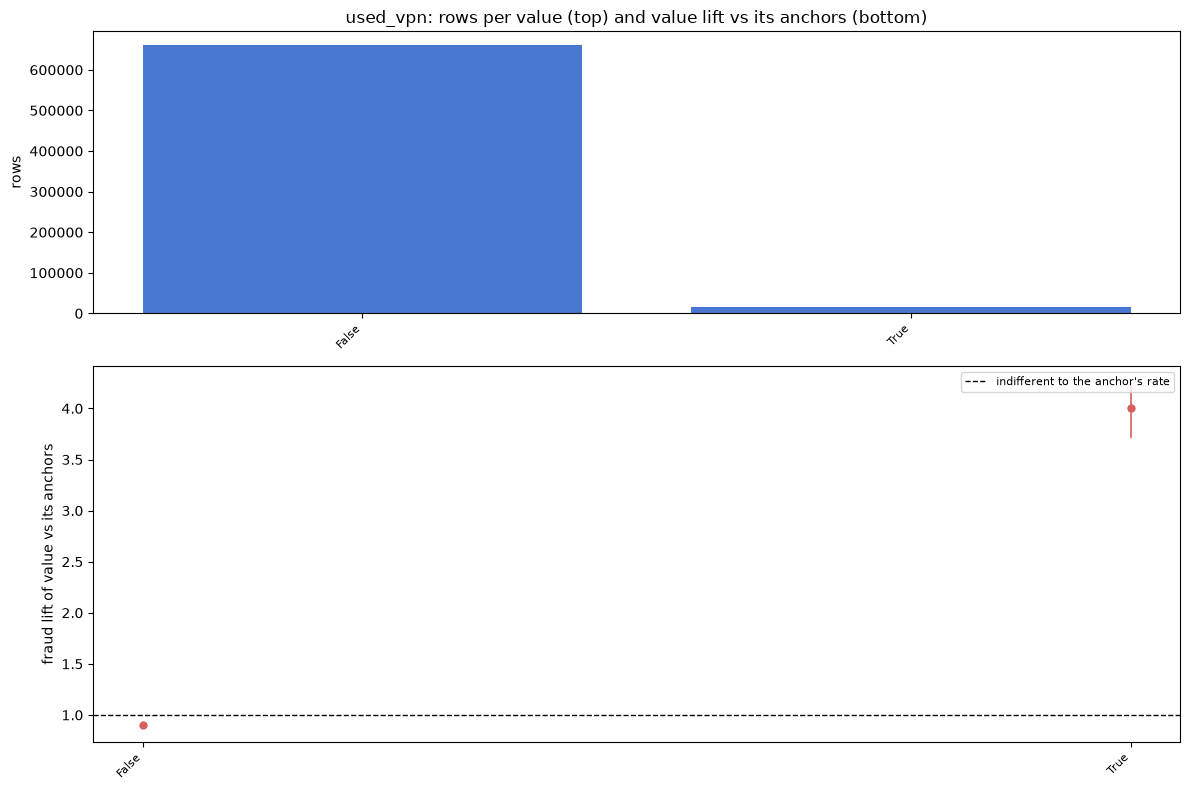

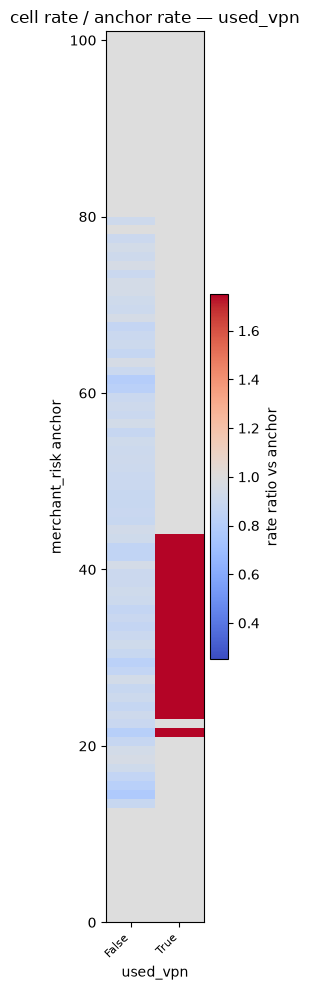

,obs,exp,n,lift
v,,,,
False,10020,11128.194,661742,0.9
True,698,174.512,14931,4.0


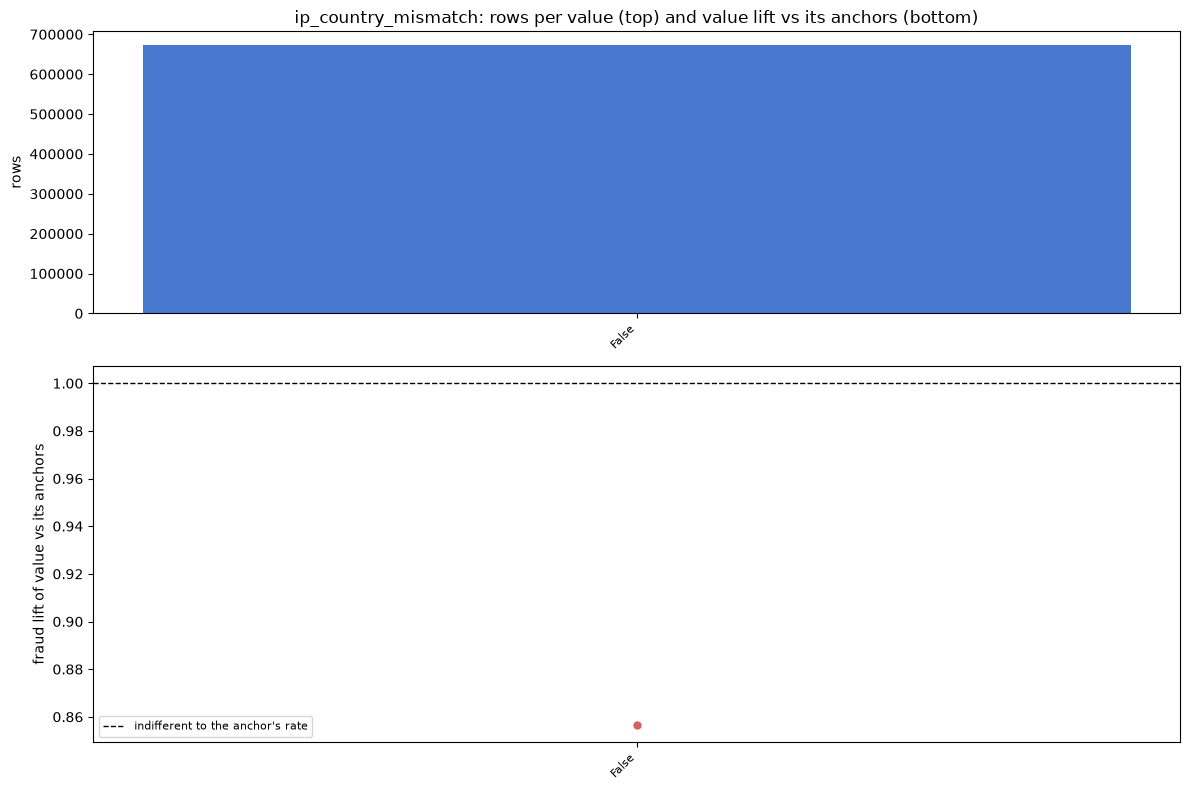

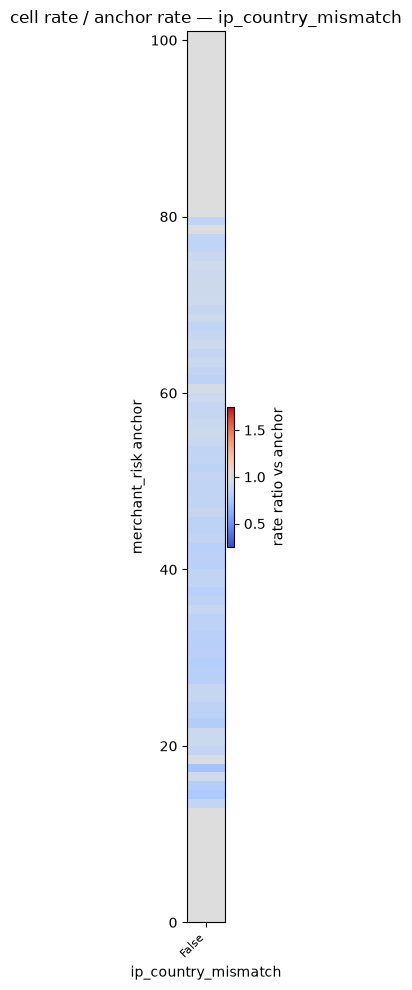

,obs,exp,n,lift
v,,,,
False,9699,11323.844,673829,0.857


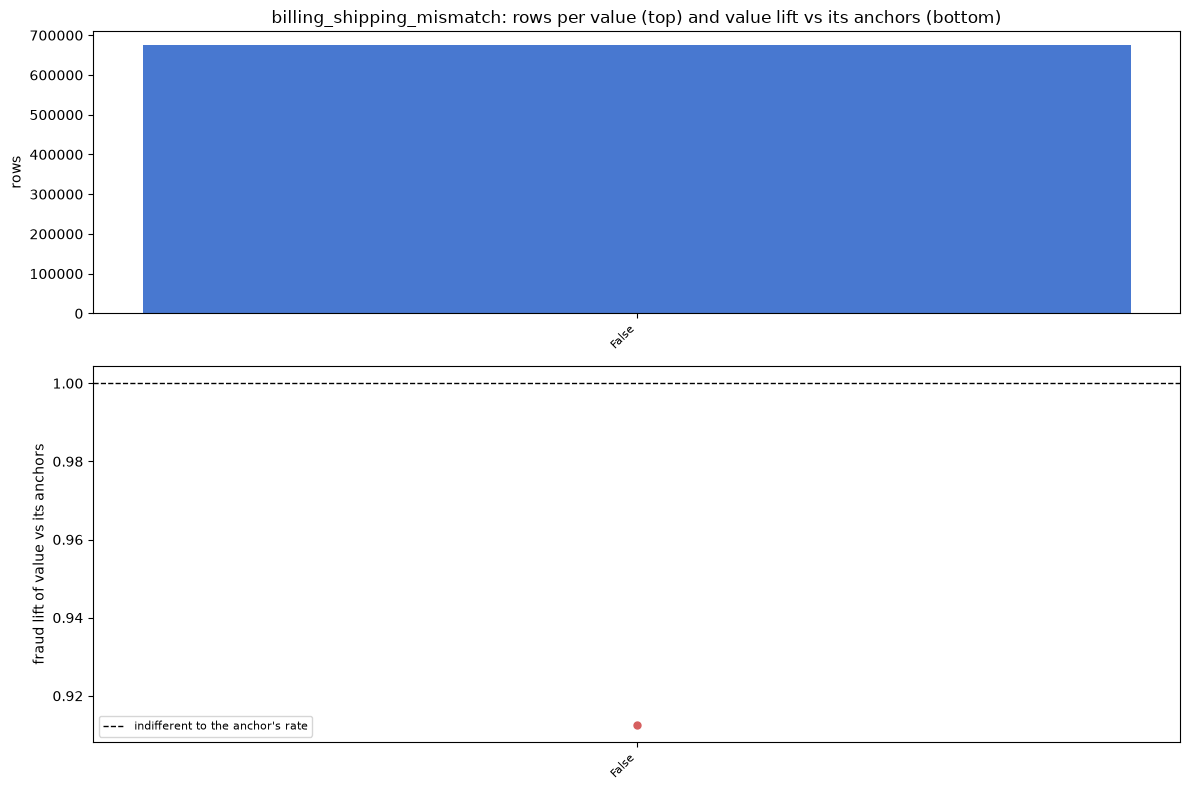

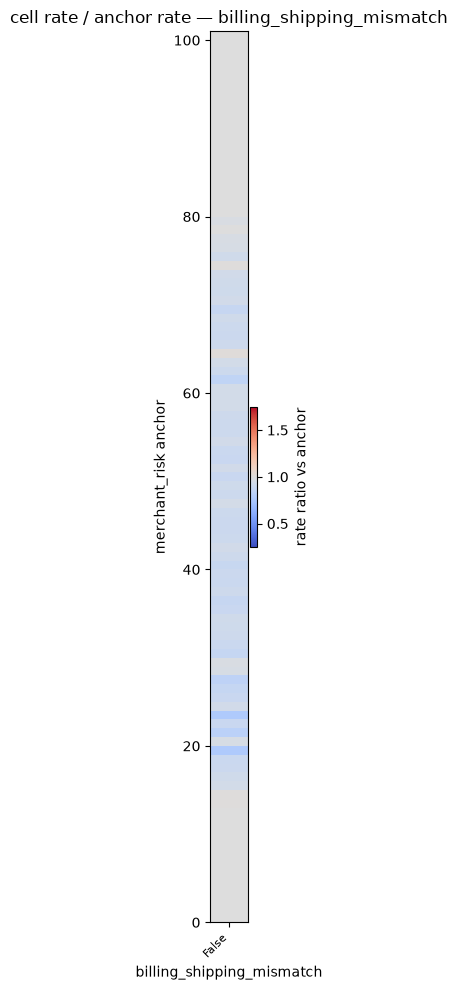

,obs,exp,n,lift
v,,,,
False,10378,11373.17,676058,0.912


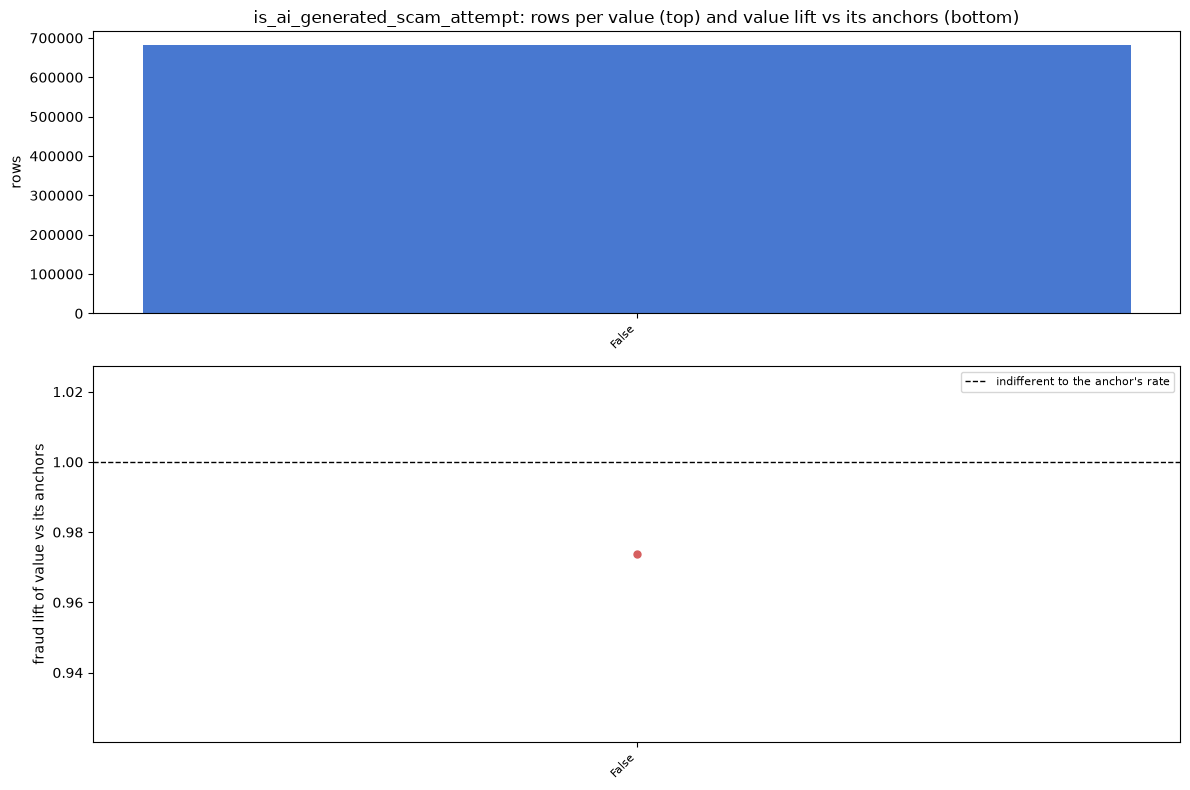

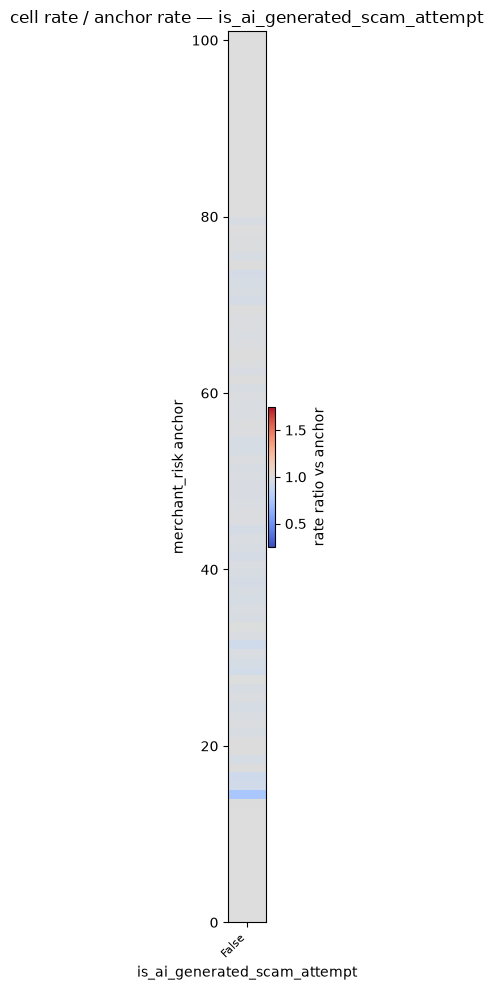

,obs,exp,n,lift
v,,,,
False,11198,11500.157,682664,0.974


In [4]:
# Test 3: value-level lift + anchor x value heat maps for meaningful partners
meaningful = scan[scan["meaningful"]]["partner"].tolist()
print("meaningful partners:", meaningful)

for partner in meaningful:
    vals = partner_arrays[partner]
    df = pd.DataFrame({"a": anchor_sorted, "v": vals, "y": y_sorted})
    cell = df.groupby(["a", "v"])["y"].agg(f="sum", n="size").reset_index()
    cell = cell[cell["n"] >= MIN_CELL_ROWS]
    cell = cell[cell["a"].map(p_anchor) > 0]   # zero-fraud anchors carry no rate to compare
    cell["exp"] = cell["n"] * cell["a"].map(p_anchor)
    grouped = cell.groupby("v").agg(obs=("f", "sum"), exp=("exp", "sum"), n=("n", "sum"))
    grouped["lift"] = grouped["obs"] / grouped["exp"]
    # bootstrap: redraw frauds per cell, accumulate per value, recompute lifts
    draws = rng.binomial(
        cell["n"].to_numpy(dtype=np.int64)[:, None],
        (cell["f"] / cell["n"]).to_numpy()[:, None],
        size=(len(cell), B),
    )
    v_codes, v_levels = pd.factorize(cell["v"])
    obs_star = np.zeros((len(v_levels), B))
    exp_star = np.zeros((len(v_levels), B))
    np.add.at(obs_star, v_codes, draws)
    np.add.at(exp_star, v_codes, np.tile(cell["exp"].to_numpy()[:, None], (1, B)))
    star = obs_star / exp_star
    lo = pd.Series(np.percentile(star, 2.5, axis=1), index=v_levels)
    hi = pd.Series(np.percentile(star, 97.5, axis=1), index=v_levels)

    fig, (ax_top, ax_bot) = plt.subplots(
        2, 1, figsize=(12, 8), gridspec_kw={"height_ratios": [1.2, 1.6]}
    )
    x = np.arange(len(grouped))
    ax_top.bar(x, grouped["n"], color="#4878d0")
    ax_top.set_xticks(x)
    ax_top.set_xticklabels([str(v) for v in grouped.index], rotation=45, ha="right", fontsize=8)
    ax_top.set_ylabel("rows")
    ax_top.set_title(f"{partner}: rows per value (top) and value lift vs its anchors (bottom)")
    ax_bot.errorbar(
        x, grouped["lift"],
        yerr=np.vstack([
            np.clip(grouped["lift"] - lo.loc[grouped.index], 0, None),
            np.clip(hi.loc[grouped.index] - grouped["lift"], 0, None),
        ]),
        fmt="o", ms=5, lw=1.2, color="#d65f5f", ecolor="#d65f5f",
    )
    ax_bot.axhline(1.0, color="black", lw=1, ls="--", label="indifferent to the anchor's rate")
    ax_bot.set_xticks(x)
    ax_bot.set_xticklabels([str(v) for v in grouped.index], rotation=45, ha="right", fontsize=8)
    ax_bot.set_ylabel("fraud lift of value vs its anchors")
    ax_bot.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(plot_dir / f"{partner}_value_lift.png", dpi=110)
    plt.show()

    # heat map: anchor x value lift, masked small cells
    values_order = [v for v in grouped.index]
    grid = np.full((len(anchor_tot), len(values_order)), np.nan)
    a_pos = {a: i for i, a in enumerate(anchor_tot.index)}
    v_pos = {v: i for i, v in enumerate(values_order)}
    for _, row in cell.iterrows():
        grid[a_pos[row["a"]], v_pos[row["v"]]] = (row["f"] / row["n"]) / p_anchor[row["a"]]
    fig, ax = plt.subplots(figsize=(1.1 + 0.75 * len(values_order), 10))
    cmap = plt.get_cmap("coolwarm").copy()
    cmap.set_bad(color="#dddddd")
    anchor_edges = np.r_[anchor_tot.index.to_numpy(), anchor_tot.index.to_numpy()[-1] + 1]
    im = ax.pcolormesh(
        np.arange(len(values_order) + 1), anchor_edges,
        grid, cmap=cmap, shading="flat", vmin=0.25, vmax=1.75,
    )
    ax.set_xticks(np.arange(len(values_order)) + 0.5)
    ax.set_xticklabels([str(v) for v in values_order], rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("merchant_risk anchor")
    ax.set_xlabel(partner)
    ax.set_title(f"cell rate / anchor rate — {partner}")
    fig.colorbar(im, ax=ax, label="rate ratio vs anchor")
    fig.tight_layout()
    fig.savefig(plot_dir / f"{partner}_anchor_value_heatmap.png", dpi=110)
    plt.show()
    display(grouped.round(3))

In [5]:
# Test 4: main effect vs interaction — does a value's lift VARY across anchors?
# Constant lift (rate(a,v) ~ rate(a) x g_v) = main effect, already in the model
# (the column itself); varying lift = genuine interaction with the anchor.
rng_h = np.random.default_rng(7)
het_rows = []
for partner in meaningful:
    vals = partner_arrays[partner]
    df = pd.DataFrame({"a": anchor_sorted, "v": vals, "y": y_sorted})
    cell = df.groupby(["a", "v"])["y"].agg(f="sum", n="size").reset_index()
    cell = cell[(cell["n"] >= MIN_CELL_ROWS) & (cell["a"].map(p_anchor) > 0)]
    for v, sub in cell.groupby("v"):
        if len(sub) < 8:
            continue
        obs = sub["f"].to_numpy(float); n = sub["n"].to_numpy(float)
        exp = n * sub["a"].map(p_anchor).to_numpy(float)
        pooled = obs.sum() / exp.sum()
        mu = exp * pooled
        t_obs = float((((obs - mu) ** 2) / mu).sum())
        null = np.empty(200)
        for b in range(200):
            sim = rng_h.binomial(n.astype(int), np.clip(mu / n, 0, 1))
            null[b] = (((sim - mu) ** 2) / mu).sum()
        p = (1 + int((null >= t_obs).sum())) / 201
        het_rows.append({
            "partner": partner, "value": str(v),
            "pooled lift": round(float(pooled), 2),
            "heterogeneity p": round(p, 3),
            "reading": "CONSTANT (main effect)" if p > 0.05 else "VARIES by anchor",
        })
het = pd.DataFrame(het_rows)
display(het)
print("values varying by anchor:", int((het['reading'] != 'CONSTANT (main effect)').sum()), "of", len(het))

,partner,value,pooled lift,heterogeneity p,reading
0,merchant_category,Electronics,0.85,0.189,CONSTANT (main effect)
1,merchant_category,Fuel,0.96,0.866,CONSTANT (main effect)
2,merchant_category,Gaming,1.10,0.607,CONSTANT (main effect)
3,merchant_category,Groceries,0.88,0.955,CONSTANT (main effect)
4,merchant_category,Healthcare,0.92,0.378,CONSTANT (main effect)
5,merchant_category,Online Retail,0.87,0.502,CONSTANT (main effect)
6,merchant_category,Restaurants,0.93,0.692,CONSTANT (main effect)
7,merchant_category,Streaming,1.66,0.731,CONSTANT (main effect)
8,merchant_category,Travel,1.37,0.154,CONSTANT (main effect)
9,merchant_category,Utilities,1.10,0.801,CONSTANT (main effect)


values varying by anchor: 1 of 23


## Interpretation

Written 2026-11-22, after execution and the Test 4 check.

- **The mixture question is answered: yes, decisively.** 8 of the 11
  categorical partners make merchant_risk anchors genuine mixtures -
  their cells deviate from the anchor's pooled rate far beyond
  within-anchor shuffle noise (is_new_merchant 100/116 cells, used_vpn
  78/94, auth_method 103/246, merchant_category 22/348; card_type,
  channel, device_type: none). Within-anchor rate variance IS explained
  by category profiling.
- **But it is all main effect, not interaction.** Test 4: every value's
  lift over its anchors is CONSTANT across anchors (all heterogeneity
  p > 0.05 except one): used_vpn True carries ~4.0x its anchor's rate
  everywhere, No Authentication ~3.7x, is_new_merchant True ~2.8x,
  Biometric ~0.30x, Streaming 1.66x. The lone exception is
  used_vpn=True (p = 0.020) - exactly what ~19 tests at the 5% level
  produce by chance; treat as noise unless fold-stable.
- **Generator reading**: P(fraud | anchor, category) ~
  P(fraud | anchor) x g(category) - the same multiplicative composition
  the joint-anchor notebook found for the numeric partner (product of
  marginals, p = 0.796). The generator composes contexts
  multiplicatively, on both the numeric and the categorical side.
- **FE consequence: stop before building.** A conditional
  (anchor x value) rate restates pooled anchor rate x a constant lift -
  both ingredients are already model inputs (arate + the categorical
  column), and a depth-6 tree assembles a constant multiplier with one
  extra split. This is the data-level explanation of why anchor_v3 was
  flat, predicted here before spending one of the 2 remaining attempts.
  v2 (rate-banded anchor groups x categories) is not justified either:
  banding anchors cannot create interactions the per-anchor test says
  do not exist.